# Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# repo root = first parent folder that contains utils/plotting_utils.py
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "utils" / "plotting_utils.py").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.plotting_utils import *
set_paper_style()
print(f"TAKE_ABS = {TAKE_ABS}; figures -> {FIG_DIR}")

TAKE_ABS = True; figures -> /home/c13745859/BrainAlign_Scripts./AlignmentMeasures/figures


In [9]:
from matplotlib import font_manager
print(font_manager.findfont(font_manager.FontProperties(family=plt.rcParams["font.family"])))

/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf


# Load data

In [2]:
df_all           = load_all()                          # main: raw (LSM from PCA-100)
df_all_signed    = load_all(take_abs=False)            # robustness
df_pca100        = load_all(n_components=PCA_MAIN)     # all measures on PCA-100
df_var_explained = load_variance_explained()

ephys: excluding measures ['LinearShape_alpha0']


/home/c13745859/BrainAlign_Scripts./AlignmentMeasures/utils/plotting_utils.py:322: UserWarning: ephys: dropping 48 duplicate rows (keeping first); 0 groups have DIFFERING scores; layers: ['avgpool', 'features.5.8.add']
  warnings.warn(


fMRI: excluding measures ['LinearShape_alpha0']
EEG time points per bin: {'50-150 ms': 5, '150-300 ms': 8, '300-450 ms': 7}
EEG: excluding measures ['LinearShape_alpha0']


/home/c13745859/BrainAlign_Scripts./AlignmentMeasures/utils/plotting_utils.py:322: UserWarning: ephys: dropping 48 duplicate rows (keeping first); 0 groups have DIFFERING scores; layers: ['avgpool', 'features.5.8.add']
  warnings.warn(


ephys: excluding measures ['LinearShape_alpha0']
fMRI: excluding measures ['LinearShape_alpha0']
EEG time points per bin: {'50-150 ms': 5, '150-300 ms': 8, '300-450 ms': 7}
EEG: excluding measures ['LinearShape_alpha0']
ephys: excluding measures ['CKA_debiased', 'LinearShape_alpha0']
fMRI: excluding measures ['CKA_debiased', 'LinearShape_alpha0']
EEG time points per bin: {'50-150 ms': 5, '150-300 ms': 8, '300-450 ms': 7}
EEG: excluding measures ['CKA_debiased', 'LinearShape_alpha0']


In [3]:
REQUIRE_COMPLETE = True

missing        = check_completeness(df_all)
missing_pca100 = check_completeness(df_pca100, measures=measures_for(PCA_MAIN))
print(f"{len(missing)} missing combinations; {len(missing_pca100)} in PCA {PCA_MAIN}")
if REQUIRE_COMPLETE:
    assert missing.empty and missing_pca100.empty, "incomplete results: see `missing`"
missing.groupby(["modality", "model", "measure"]).size()

0 missing combinations; 0 in PCA 100


Series([], dtype: int64)

# Results

## Correlation maps

In [4]:
# --- main: within-profile ---
cor_maps    = cormaps(df_all, group_by=WITHIN)
cor_overall = average_maps(cor_maps)
cor_mean    = mean_agreement(cor_overall)
cor_sim     = map_similarity(cor_maps)
cor_stats   = cormap_stats_all(df_all, group_by=WITHIN)

# --- supplement: pooled ---
cor_maps_pooled  = cormaps(df_all)
cor_sim_pooled   = map_similarity(cor_maps_pooled)
cor_stats_pooled = cormap_stats_all(df_all)

# --- supplement: per brain depth (within-profile) ---
cor_maps_depth  = {d: cormaps(df_all, depth=d, group_by=WITHIN) for d in DEPTH_ORDER}
cor_stats_depth = cormap_stats_by_depth(df_all, group_by=WITHIN)   # FDR joint across depths

# --- robustness (within-profile) ---
cor_maps_signed = cormaps(df_all_signed, group_by=WITHIN)
cor_maps_pca100 = cormaps(df_pca100, group_by=WITHIN)

cor_sim

only 2 subjects: no subject-level inference
only 2 subjects: no subject-level inference
only 2 subjects: no subject-level inference
only 2 subjects: no subject-level inference
only 2 subjects: no subject-level inference


,pair,rho,p_perm,p_fdr
0,Ephys - fMRI,0.875161,0.0001,0.00015
1,Ephys - EEG,0.852767,0.0003,0.00030
2,fMRI - EEG,0.845817,0.0001,0.00015


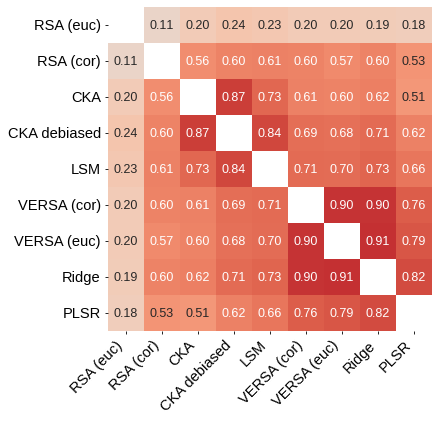

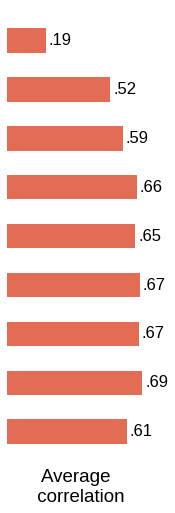

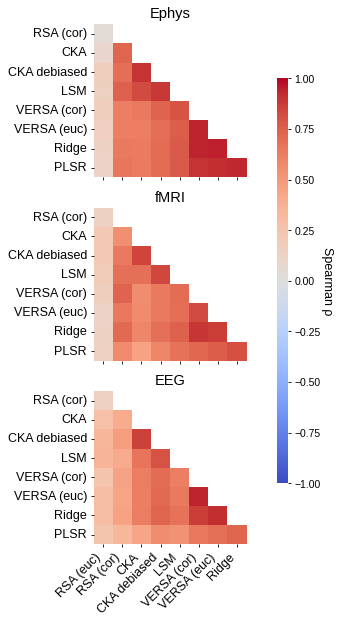

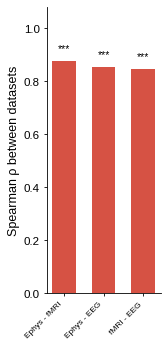

In [5]:
# main: within-profile
_ = cormap_figure_set(cor_maps, tag="within_profile", sim=cor_sim, stats=cor_stats)

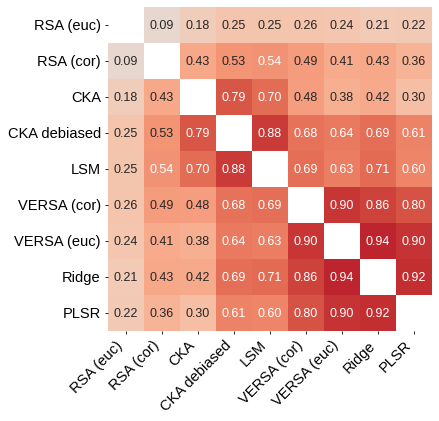

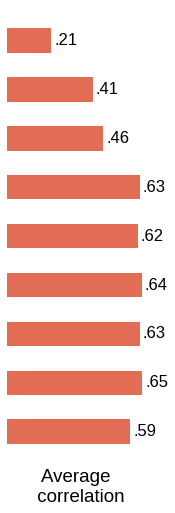

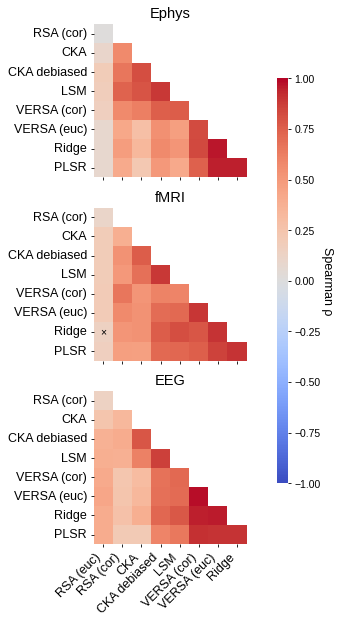

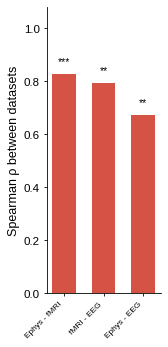

In [6]:
# supplement: pooled
_ = cormap_figure_set(cor_maps_pooled, tag="pooled", sim=cor_sim_pooled, stats=cor_stats_pooled)

--- early: V1, 50-150 ms ---


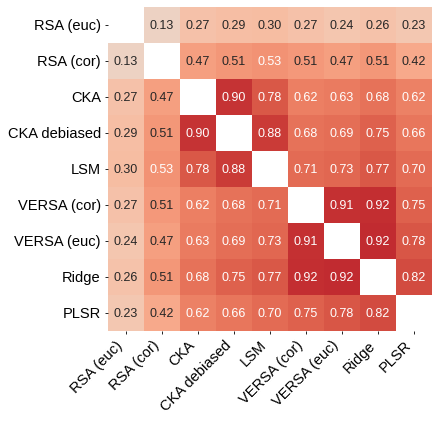

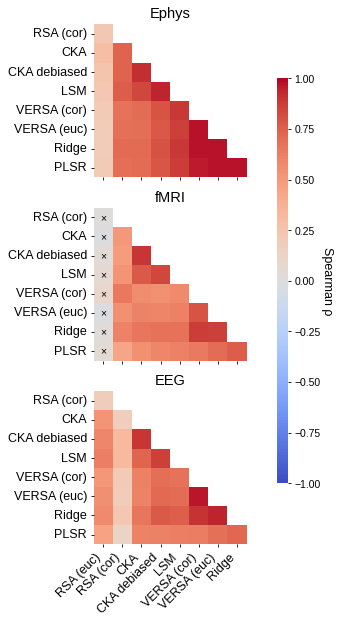

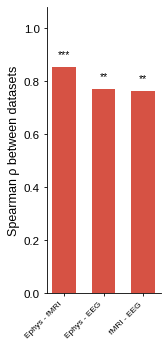

--- mid: V4, 150-300 ms ---


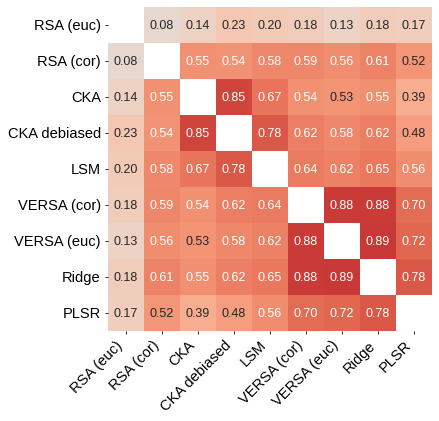

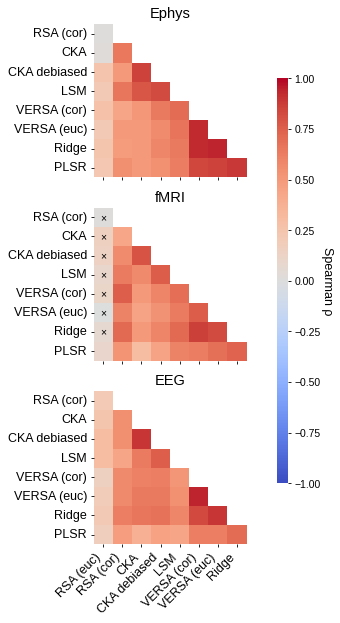

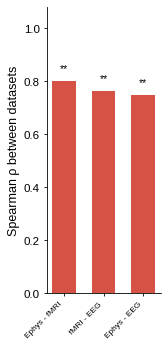

--- late: IT, FFA, 300-450 ms ---


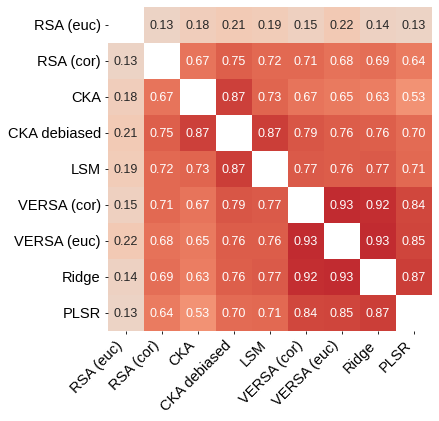

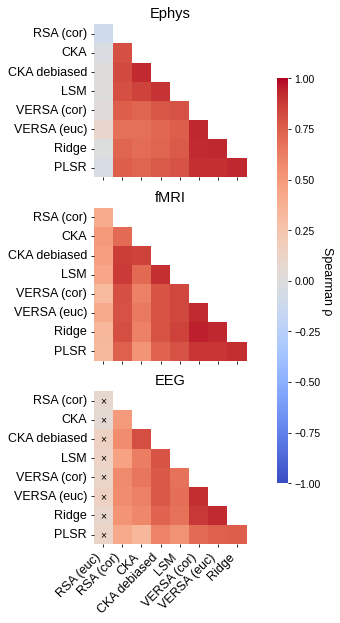

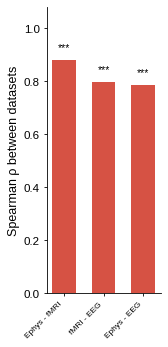

In [7]:
# supplement: per brain depth
for depth in DEPTH_ORDER:
    print(f"--- {depth}: {DEPTH_LABELS[depth]} ---")
    _ = cormap_figure_set(
        cor_maps_depth[depth],
        tag=f"within_profile_depth_{depth}",
        stats=cor_stats_depth[cor_stats_depth["brain_depth"] == depth],
        panels=("overall", "by_modality", "similarity"),     # mean-agreement bars: next cell
    )

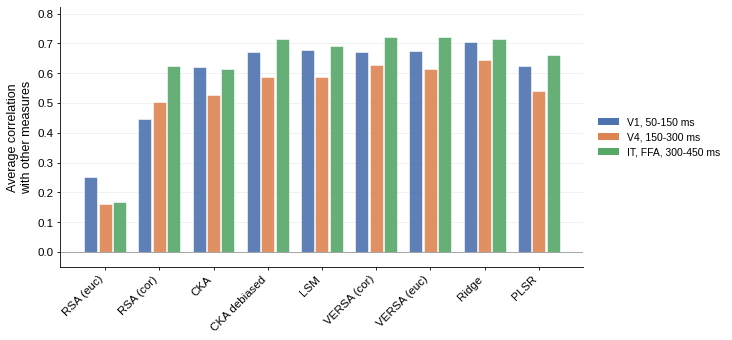

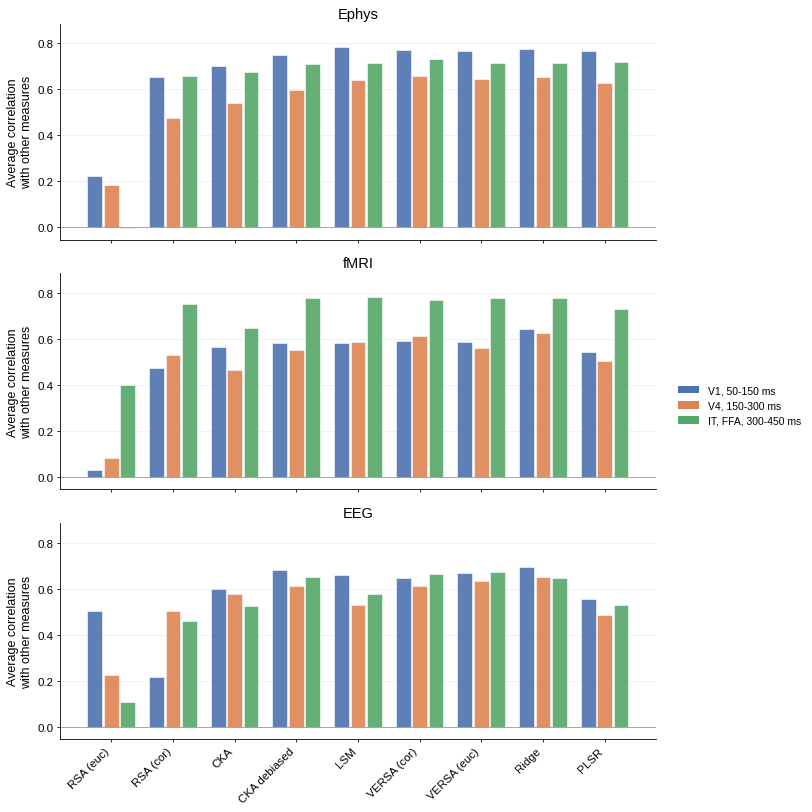

In [8]:
# summary across modalities
fig = plot_mean_agreement_by_depth(cor_maps_depth)                 # add cor_overall for the dashed line
save_fig(fig, "within_profile_mean_agreement_by_depth")

# per modality
fig = plot_mean_agreement_by_depth_stacked(cor_maps_depth)         # add overall_maps=cor_maps for lines
save_fig(fig, "within_profile_mean_agreement_by_depth_by_modality")
plt.show()

## PCA sensitivity

In [ ]:
# ===== Exploratory: RSA computed on PCA-100 features =====
EXPLORE_MODS   = MODALITY_ORDER        # drop a modality here if its PCA results are incomplete
RSA_PCA_LABELS = {"RSA_euc": "RSA (euc) + PCA", "RSA_cor": "RSA (cor) + PCA"}

# standard and PCA-RSA versions on the same rows
df_rsa_std, df_rsa_pca = match_pca_rows(df_all, df_pca100, swap=RSA_MEASURES, modalities=EXPLORE_MODS)

_ = pca_comparison_figures(df_rsa_std, df_rsa_pca, RSA_PCA_LABELS, highlight=RSA_MEASURES,
                           tag="explore_rsa_pca100_within_profile", frame=True,
                           modalities=EXPLORE_MODS)

# change in RSA's correlations with the other measures
rsa_diff, rsa_diff_summary = pca_rsa_pair_changes(df_rsa_std, df_rsa_pca, modalities=EXPLORE_MODS)
rsa_diff_summary.round(3)

In [ ]:
# ===== Exploratory: all measures on PCA-100 features vs standard =====
pca_measures = present_measures(df_pca100[df_pca100["modality"].isin(EXPLORE_MODS)])   # no CKA debiased
ALL_PCA_LABELS = {m: f"{MEASURE_NAMES[m]} + PCA" for m in pca_measures}
ALL_PCA_LABELS["LinearShape_alpha1"] += "*"          # PCA-100 in the standard analysis too
print(f"measures in this comparison: {pca_measures}")

df_cmp_std, df_cmp_pca = match_pca_rows(df_all[df_all["measure"].isin(pca_measures)], df_pca100,
                                        swap=pca_measures, modalities=EXPLORE_MODS)

_ = pca_comparison_figures(df_cmp_std, df_cmp_pca, ALL_PCA_LABELS, highlight=pca_measures,
                           tag="explore_all_pca100_within_profile", modalities=EXPLORE_MODS)

In [ ]:
# ===== PCA sensitivity: RSA, CKA across component counts =====
df_sweep = load_sweep(df_all)

stab_maps    = {m: stability_maps(df_sweep, m) for m in PCA_MEASURES}
stab_overall = {m: average_maps(maps) for m, maps in stab_maps.items()}
stab_to_ref  = stability_to_ref(stab_maps)
stab_to_ref.round(2)

In [ ]:
fig = plot_stability_maps(stab_overall)
save_fig(fig, "pca_stability_maps")

fig = plot_stability_to_ref(stab_to_ref)
save_fig(fig, "pca_stability_to_reference")
plt.show()

In [ ]:
# hierarchical correspondence across component counts
bl_sweep      = best_layers_sweep(df_sweep)
bl_sweep_summ = sweep_best_summary(bl_sweep)
hier_summ     = hierarchy_summary(bl_sweep)

hier_summ.pivot_table(index=["measure", "modality"], columns="n_components",
                      values="gap").reindex(columns=N_ORDER).round(2)

In [ ]:
fig = plot_sweep_best_layers(bl_sweep_summ)
save_fig(fig, "pca_sweep_best_layers")

fig = plot_hierarchy_gap(hier_summ)
save_fig(fig, "pca_sweep_hierarchy_gap")
plt.show()

hier_summ.pivot_table(index=["measure", "modality"], columns="n_components",
                      values="ordered").reindex(columns=N_ORDER).round(2)

## ROI profile analysis

In [ ]:
# ===== Level agreement: do measures agree on which models / regions align more? =====
df_level     = level_table(df_all, "mean")
df_level_max = level_table(df_all, "max")

cor_maps_level     = cormaps(df_level)
cor_stats_level    = cormap_stats_all(df_level)
cor_sim_level      = map_similarity(cor_maps_level)
cor_maps_level_max = cormaps(df_level_max)

# average agreement per measure in each version
agreement_versions = pd.DataFrame({
    "within_profile":     mean_agreement(cor_overall),
    "pooled":             mean_agreement(average_maps(cor_maps_pooled)),
    "level (mean)":       mean_agreement(average_maps(cor_maps_level)),
    "level (best layer)": mean_agreement(average_maps(cor_maps_level_max)),
}).round(2)
print(agreement_versions)

In [ ]:
_ = cormap_figure_set(cor_maps_level, tag="level", sim=cor_sim_level, stats=cor_stats_level)

In [ ]:
# ===== Relative region profiles =====
rel         = relative_region_profiles(df_all)
rel_summary = summarise_relative(rel)
rel_tests   = relative_contrast_tests(rel)

# check: measures whose mean level is close to zero make the ratio unstable
display(level_table(df_all, REL_HOW).groupby(["modality", "measure"], observed=True)["score"]
        .mean().unstack("modality").round(3))
rel_tests.round(3)

In [ ]:
fig = plot_relative_profiles(rel_summary)                         # averaged over models
save_fig(fig, "relative_region_profiles")

fig = plot_relative_profiles(rel_summary, models=MODEL_ORDER)     # per model: consistency
save_fig(fig, "relative_region_profiles_by_model")
plt.show()

## Hierarchical correspondence

In [ ]:
prof            = depth_profiles(df_all)
prof_scaled     = scaled_profiles(prof)                     # as in the old figure
prof_scaled_sf  = scaled_profiles(prof, scale_first=True)   # check: scale each modality first
cons, cons_mean = profile_consistency(prof)
cons_mean.round(2)

In [ ]:
fig = plot_depth_profiles(prof_scaled)
save_fig(fig, "depth_profiles")

fig = plot_profile_legend(present_measures(df_all))
save_fig(fig, "depth_profiles_legend")

fig = plot_consistency(cons, cons_mean)
save_fig(fig, "profile_consistency")

# # check: scale each modality before averaging
# fig = plot_depth_profiles(prof_scaled_sf)
# save_fig(fig, "depth_profiles_scale_first")

plt.show()

In [ ]:
best         = best_layers(df_all)
best_summary = best_layer_summary(best)
fig = plot_hierarchical_correspondence(best_summary, legend=False)
save_fig(fig, "hierarchical_correspondence")

In [ ]:
best_summary_signed = best_layer_summary(best_layers(df_all_signed))
fig = plot_hierarchical_correspondence(best_summary_signed)
save_fig(fig, "hierarchical_correspondence_signed")
plt.show()

## Within block patterns

### Variance decomposition

In [ ]:
lt = layer_table(df_all)
check_balance(lt)
var_decomp = variance_decomposition_table(lt)
pattern    = block_pattern_table(df_all)

var_decomp.groupby("model", observed=True)[["chance_block", "chance_layertype"]].mean().round(3)

In [ ]:
fig = plot_variance_decomposition(var_decomp)
fig.legend(handles=variance_legend_handles(), loc="center left",
           bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=10)
save_fig(fig, "variance_decomposition")

fig = plot_variance_by_modality(var_decomp)
save_fig(fig, "variance_decomposition_by_modality")

# fig = plot_block_pattern(pattern, measures=["Ridge"])
# save_fig(fig, "block_pattern_ridge")

plt.show()

### Variance decomposition test

In [ ]:
# ===== Layer structure: global vs local pattern, with noise estimated from subjects =====
sl = subject_layer_table(df_all)
check_balance(sl)
ls_points, ls_boots = layer_structure_analysis(sl)
ls_summary     = summarise_layer_structure(ls_points, ls_boots)                   # fMRI + EEG, CIs
ls_summary_mod = summarise_layer_structure(ls_points, ls_boots, by=("modality", "measure"),
                                           modalities=MODALITY_ORDER)             # ephys descriptive
ls_summary.pivot(index="measure", columns="stat", values="point").round(3)

In [ ]:
fig = plot_layer_structure(ls_summary)
save_fig(fig, "layer_structure_components")

fig = plot_stat_by_measure(ls_summary, "dominance",
                           "between-block − layer type\n(fraction of variance)")
save_fig(fig, "layer_structure_dominance")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
plot_stat_by_measure(ls_summary, "slope_z", "change in Add peak per network depth\n(within-block z)", ax=axes[0])
plot_stat_by_measure(ls_summary, "slope_prof", "change in Add peak per network depth\n(profile SD)", ax=axes[1])
fig.tight_layout()
save_fig(fig, "layer_structure_add_peak_slope")

fig = plot_stage_patterns(stage_patterns(sl))
save_fig(fig, "layer_structure_stage_patterns")
plt.show()

### Residual blocks

In [ ]:
zs = block_zscores(df_all)
lt_profiles = layer_type_profiles(zs)

# old-notebook version, for comparison
lt_profiles_old = layer_type_profiles(block_zscores(df_all, zscore_over="all_in_block"))

In [ ]:
fig = plot_layer_type_pattern(lt_profiles)
save_fig(fig, "layer_type_pattern")
plt.show()

# comparison with the old z-scoring (not for the paper)
fig = plot_layer_type_pattern(lt_profiles_old)
plt.show()

## Supplementary material

In [ ]:
# ===== Appendix: classical PCA curves (score vs number of components) =====
pca_curves       = pca_score_curves(df_sweep)                         # pooled over regions and models
pca_curves_depth = pca_score_curves(df_sweep, split="brain_depth")
pca_curves_model = pca_score_curves(df_sweep, split="model")
pca_curves_mean  = pca_score_curves(df_sweep, how="mean")             # check: mean over layers

In [ ]:
fig = plot_pca_curves_pooled(pca_curves)
save_fig(fig, "pca_curves_pooled")

fig = plot_pca_curves_pooled(pca_curves_mean, ylabel="mean score over layers")
save_fig(fig, "pca_curves_pooled_mean")

# fig = plot_pca_curves_split(pca_curves_depth, "brain_depth")
# save_fig(fig, "pca_curves_by_depth")

# fig = plot_pca_curves_split(pca_curves_model, "model")
# save_fig(fig, "pca_curves_by_model")
# plt.show()

In [ ]:
# positions are column labels; the plot takes its columns from this dict
SAMPLED_LAYERS = {
    "alexnet":       {"early": "Conv1",      "mid": "Conv3",                "late": "FullyConnected2"},
    "resnet50":      {"early": "conv1",      "mid": "layer3.2.conv2",       "late": "layer4.1.conv2"},
    "convnext_tiny": {"early": "features.0", "mid": "features.5.4.block.0", "late": "features.7.1.block.0"},
}

sampled = sample_layers(SAMPLED_LAYERS, df_sweep)
display(sampled)
layer_curves  = layer_pca_curves(df_sweep, sampled)
var_explained = variance_explained_lookup(df_var_explained)

In [ ]:
for mod in MODALITY_ORDER:
    for model in MODEL_ORDER:
        fig = plot_layer_pca_curves(layer_curves, sampled, mod, model, var_explained)
        save_fig(fig, f"pca_curves_layers_{mod}_{model}")
plt.show()

# Save results for the figures notebook

In [ ]:
FIGURE_INPUTS = [
    # correlation maps
    "cor_maps", "cor_sim", "cor_stats",
    "cor_maps_pooled", "cor_sim_pooled", "cor_stats_pooled",
    "cor_maps_depth", "cor_stats_depth",
    # hierarchical correspondence
    "prof_scaled", "cons", "cons_mean", "best_summary", "best_summary_signed",
    # layer structure
    "var_decomp", "ls_summary", "lt_profiles",
    # supplement
    "rel_summary", "stab_overall", "stab_to_ref", "bl_sweep_summ", "hier_summ",
    "pca_curves", "pca_curves_mean", "layer_curves", "sampled", "var_explained",
]
save_tables({name: globals()[name] for name in FIGURE_INPUTS})